<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook10_Learning_Curves_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (KFold, cross_val_score, learning_curve,
                                     validation_curve, GridSearchCV)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = "neg_root_mean_squared_error"
base_rmse = -cross_val_score(DummyRegressor(), X_all, y, cv=cv, scoring=scoring).mean()
print("Train:", train.shape, "| baseline CV RMSE (predict the mean):", round(base_rmse, 3))

Train: (285, 42) | baseline CV RMSE (predict the mean): 3.255


degree 1: train RMSE 0.915 | other students RMSE 0.860
degree 3: train RMSE 0.877 | other students RMSE 0.899
degree 9: train RMSE 0.673 | other students RMSE 1.120


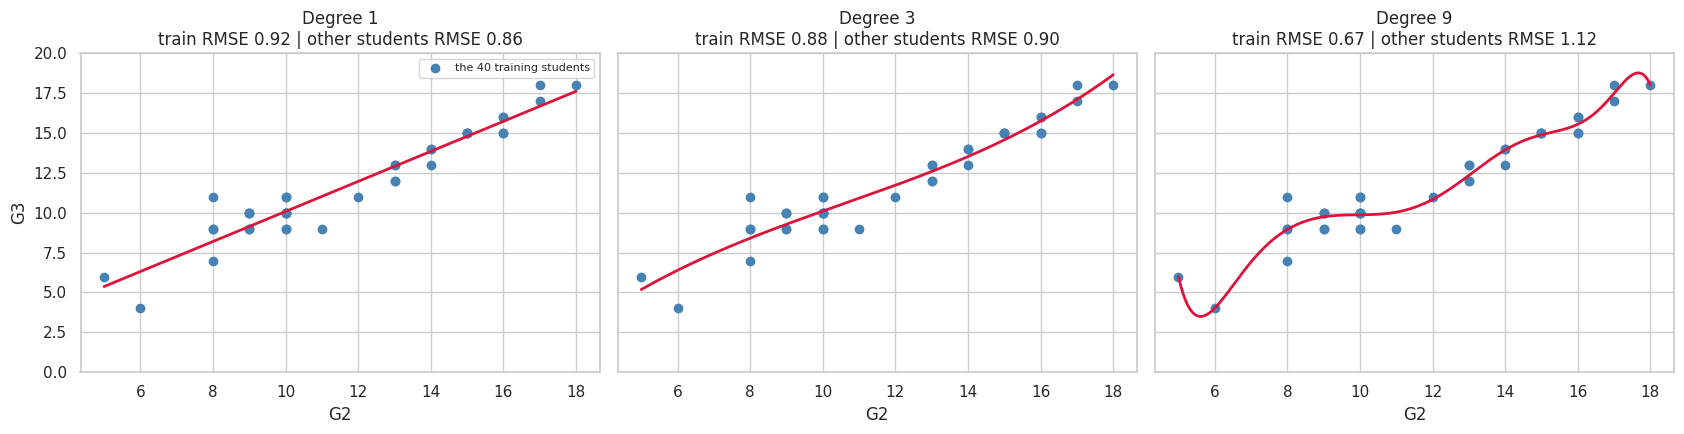

In [3]:
# Cell 2: underfitting and overfitting you can see (G2 -> G3, only 40 students to learn from)
rng = np.random.default_rng(1)
idx = rng.choice(len(train), 40, replace=False)
small = train.iloc[idx]
rest = train.drop(train.index[idx])

xs = ((small["G2"] - 10) / 5).values.reshape(-1, 1)     # scaled to keep powers tame
ys = small["G3"].values
lo, hi = xs.min(), xs.max()

xr_all = ((rest["G2"] - 10) / 5).values.reshape(-1, 1)
inside = ((xr_all >= lo) & (xr_all <= hi)).ravel()      # judge only where the model has seen data
xr, yr = xr_all[inside], rest["G2"].index[inside]
yr = rest.loc[yr, "G3"].values

grid = np.linspace(lo, hi, 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, d in zip(axes, [1, 3, 9]):
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(xs, ys)
    tr_e = np.sqrt(mean_squared_error(ys, m.predict(xs)))
    te_e = np.sqrt(mean_squared_error(yr, m.predict(xr)))
    ax.scatter(xs * 5 + 10, ys, color="steelblue", label="the 40 training students")
    ax.plot(grid * 5 + 10, m.predict(grid), color="crimson", linewidth=2)
    ax.set_title(f"Degree {d}\ntrain RMSE {tr_e:.2f} | other students RMSE {te_e:.2f}")
    ax.set_xlabel("G2"); ax.set_ylim(0, 20)
    print(f"degree {d}: train RMSE {tr_e:.3f} | other students RMSE {te_e:.3f}")
axes[0].set_ylabel("G3"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("underfit_overfit.png", dpi=150, bbox_inches="tight")
plt.show()

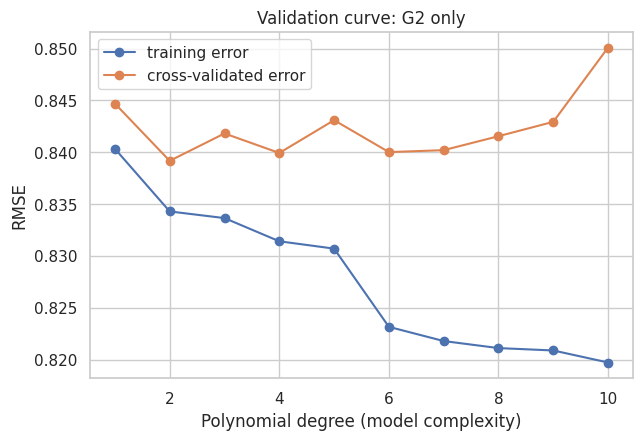

Best degree by CV: 2 | CV RMSE: 0.839


In [4]:
# Cell 3: validation curve for model complexity (polynomial degree on G2, all training students)
degrees = np.arange(1, 11)
Xg = ((train[["G2"]] - 10) / 5).values
poly = make_pipeline(PolynomialFeatures(), LinearRegression())
tr, va = validation_curve(poly, Xg, y, param_name="polynomialfeatures__degree",
                          param_range=degrees, cv=cv, scoring=scoring)
tr, va = -tr.mean(axis=1), -va.mean(axis=1)

plt.figure(figsize=(7, 4.5))
plt.plot(degrees, tr, "o-", label="training error")
plt.plot(degrees, va, "o-", label="cross-validated error")
plt.xlabel("Polynomial degree (model complexity)"); plt.ylabel("RMSE")
plt.title("Validation curve: G2 only")
plt.legend()
plt.savefig("validation_poly.png", dpi=150, bbox_inches="tight")
plt.show()
print("Best degree by CV:", degrees[int(np.argmin(va))], "| CV RMSE:", va.min().round(3))

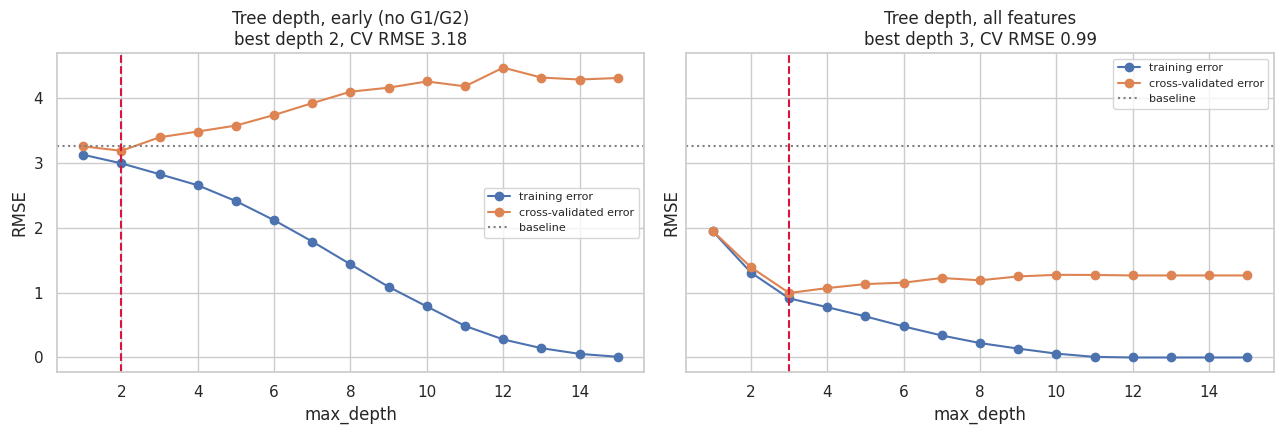

{'early (no G1/G2)': np.int64(2), 'all features': np.int64(3)}


In [5]:
# Cell 4: validation curve for a decision tree, depth is the complexity knob
depths = np.arange(1, 16)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
best_depth = {}
for ax, (name, X) in zip(axes, feature_sets.items()):
    tr, va = validation_curve(DecisionTreeRegressor(random_state=42), X, y,
                              param_name="max_depth", param_range=depths,
                              cv=cv, scoring=scoring)
    tr, va = -tr.mean(axis=1), -va.mean(axis=1)
    best_depth[name] = depths[int(np.argmin(va))]
    ax.plot(depths, tr, "o-", label="training error")
    ax.plot(depths, va, "o-", label="cross-validated error")
    ax.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
    ax.axvline(best_depth[name], color="crimson", linestyle="--")
    ax.set_title(f"Tree depth, {name}\nbest depth {best_depth[name]}, CV RMSE {va.min():.2f}")
    ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("validation_tree.png", dpi=150, bbox_inches="tight")
plt.show()
print(best_depth)

Ridge, early features                      final train 2.58 | final CV 3.02 | gap 0.44
Ridge, all features                        final train 0.76 | final CV 0.91 | gap 0.15
Deep tree (no limit), all features         final train 0.00 | final CV 1.26 | gap 1.26
Shallow tree (depth 3), all features       final train 0.91 | final CV 0.99 | gap 0.08


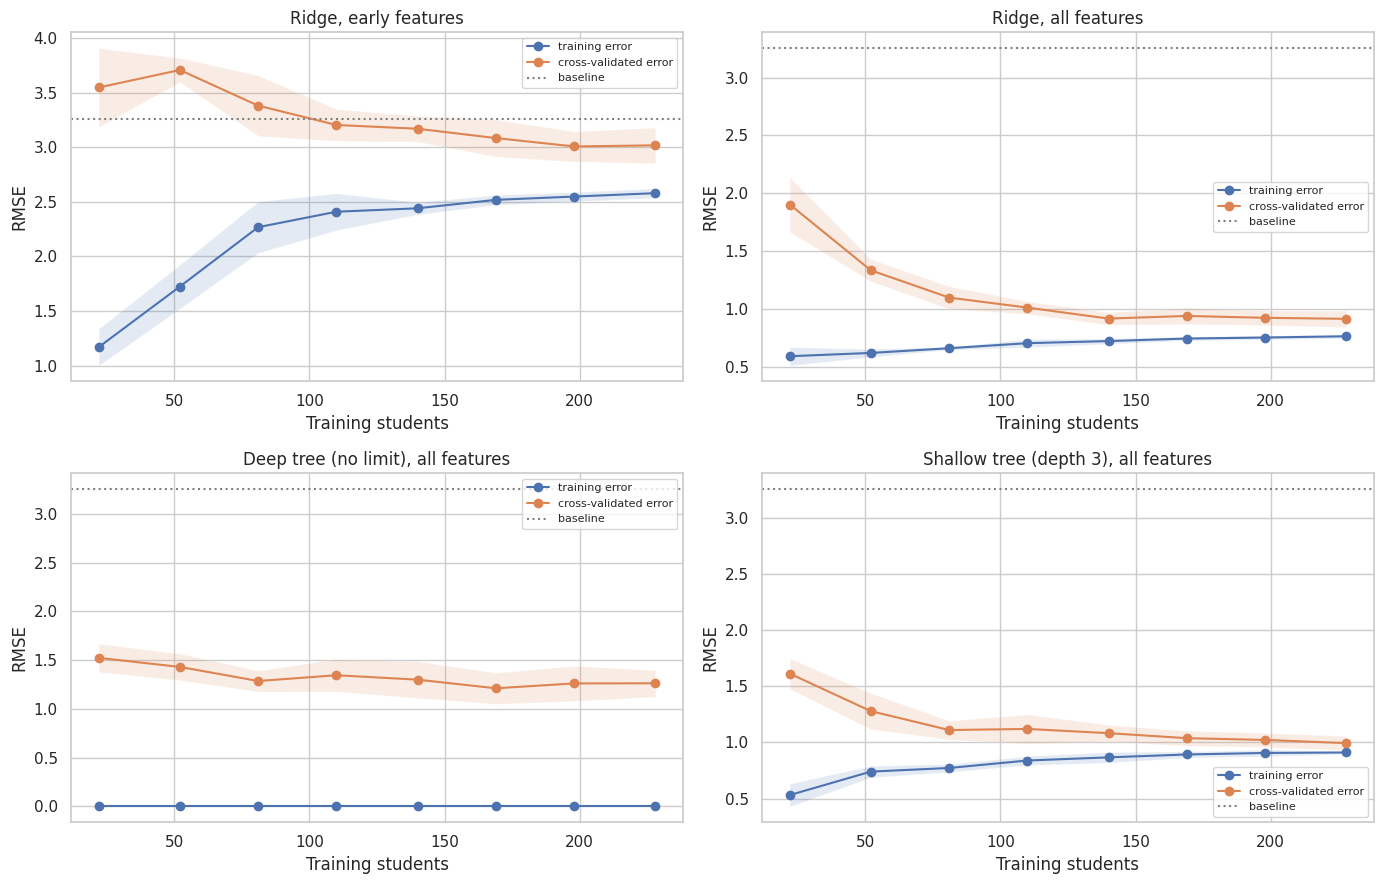

In [6]:
# Cell 5: learning curves, would more students help?
def plot_lc(ax, model, X, title):
    sizes, tr, va = learning_curve(model, X, y, cv=cv, scoring=scoring,
                                   train_sizes=np.linspace(0.1, 1.0, 8),
                                   shuffle=True, random_state=42)
    tr, va = -tr, -va
    ax.plot(sizes, tr.mean(axis=1), "o-", label="training error")
    ax.fill_between(sizes, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.15)
    ax.plot(sizes, va.mean(axis=1), "o-", label="cross-validated error")
    ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15)
    ax.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
    ax.set_title(title); ax.set_xlabel("Training students"); ax.set_ylabel("RMSE")
    ax.legend(fontsize=8)
    print(f"{title:42s} final train {tr.mean(axis=1)[-1]:.2f} | final CV {va.mean(axis=1)[-1]:.2f}"
          f" | gap {va.mean(axis=1)[-1] - tr.mean(axis=1)[-1]:.2f}")

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_lc(axes[0, 0], ridge, X_early, "Ridge, early features")
plot_lc(axes[0, 1], ridge, X_all, "Ridge, all features")
plot_lc(axes[1, 0], DecisionTreeRegressor(random_state=42), X_all, "Deep tree (no limit), all features")
plot_lc(axes[1, 1], DecisionTreeRegressor(max_depth=3, random_state=42), X_all, "Shallow tree (depth 3), all features")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Cell 6: GridSearchCV for the decision tree
tree_grid = {"max_depth": [2, 3, 4, 5, 6, 8],
             "min_samples_leaf": [1, 5, 10, 20]}
tuned = {}

for name, X in feature_sets.items():
    gs = GridSearchCV(DecisionTreeRegressor(random_state=42), tree_grid,
                      cv=cv, scoring=scoring, n_jobs=-1).fit(X, y)
    tuned[("Tree", name)] = gs
    print(f"\n{name}: best {gs.best_params_} | CV RMSE {-gs.best_score_:.3f}")
    res = pd.DataFrame(gs.cv_results_)
    res["RMSE"] = -res["mean_test_score"]
    print(res.sort_values("RMSE")[["param_max_depth", "param_min_samples_leaf", "RMSE"]]
          .head(5).round(3).to_string(index=False))


early (no G1/G2): best {'max_depth': 2, 'min_samples_leaf': 5} | CV RMSE 3.175
 param_max_depth  param_min_samples_leaf  RMSE
               2                       5 3.175
               2                       1 3.183
               2                      20 3.221
               3                      20 3.237
               4                      20 3.240

all features: best {'max_depth': 5, 'min_samples_leaf': 10} | CV RMSE 0.914
 param_max_depth  param_min_samples_leaf  RMSE
               5                      10 0.914
               6                      10 0.916
               8                      10 0.916
               4                      10 0.922
               4                       5 0.987


In [8]:
# Cell 7: GridSearchCV for Ridge (a pipeline, so the parameter is named step__parameter)
ridge_pipe = make_pipeline(StandardScaler(), Ridge())
ridge_grid = {"ridge__alpha": np.logspace(-2, 3, 20)}

for name, X in feature_sets.items():
    gs = GridSearchCV(ridge_pipe, ridge_grid, cv=cv, scoring=scoring, n_jobs=-1).fit(X, y)
    tuned[("Ridge", name)] = gs
    print(f"{name}: best alpha {gs.best_params_['ridge__alpha']:.2f} | CV RMSE {-gs.best_score_:.3f}")

early (no G1/G2): best alpha 88.59 | CV RMSE 2.950
all features: best alpha 2.34 | CV RMSE 0.902


In [9]:
# Cell 8: nested CV, an honest estimate of "tune, then predict new students"
outer = KFold(n_splits=5, shuffle=True, random_state=7)     # different folds from the inner loop
estimators = {"Tree": (DecisionTreeRegressor(random_state=42), tree_grid),
              "Ridge": (ridge_pipe, ridge_grid)}

rows = []
for (mname, fname), gs in tuned.items():
    est, grid_ = estimators[mname]
    nested = -cross_val_score(GridSearchCV(est, grid_, cv=cv, scoring=scoring, n_jobs=-1),
                              feature_sets[fname], y, cv=outer, scoring=scoring)
    rows.append({"model": mname, "features": fname,
                 "best CV RMSE (optimistic)": round(-gs.best_score_, 3),
                 "nested CV RMSE (honest)": round(nested.mean(), 3),
                 "std": round(nested.std(), 3)})
nested_table = pd.DataFrame(rows).sort_values(["features", "model"])
nested_table

,model,features,best CV RMSE (optimistic),nested CV RMSE (honest),std
3,Ridge,all features,0.902,0.896,0.068
1,Tree,all features,0.914,0.951,0.084
2,Ridge,early (no G1/G2),2.950,2.948,0.283
0,Tree,early (no G1/G2),3.175,3.191,0.328


In [10]:
# Cell 9: how much did tuning actually buy us?
default_rows = []
for fname, X in feature_sets.items():
    for mname, est in [("Tree", DecisionTreeRegressor(random_state=42)),
                       ("Ridge", make_pipeline(StandardScaler(), Ridge()))]:
        s = -cross_val_score(est, X, y, cv=outer, scoring=scoring).mean()
        default_rows.append({"model": mname, "features": fname, "default settings RMSE": round(s, 3)})
comparison = pd.DataFrame(default_rows).merge(nested_table, on=["model", "features"])
comparison["gain from tuning"] = (comparison["default settings RMSE"]
                                  - comparison["nested CV RMSE (honest)"]).round(3)
comparison[["model", "features", "default settings RMSE", "nested CV RMSE (honest)", "gain from tuning"]]

,model,features,default settings RMSE,nested CV RMSE (honest),gain from tuning
0,Tree,early (no G1/G2),4.412,3.191,1.221
1,Ridge,early (no G1/G2),3.077,2.948,0.129
2,Tree,all features,1.191,0.951,0.240
3,Ridge,all features,0.889,0.896,-0.007


In [11]:
# Cell 10: save the tuned settings for later days
def clean(d):
    return {k: (float(v) if isinstance(v, np.floating) else int(v) if isinstance(v, np.integer) else v)
            for k, v in d.items()}

best = {f"{m} | {f}": clean(gs.best_params_) for (m, f), gs in tuned.items()}
with open("best_params_day14.json", "w") as f:
    json.dump(best, f, indent=2)

nested_table.to_csv("tuning_results.csv", index=False)
print(json.dumps(best, indent=2))

{
  "Tree | early (no G1/G2)": {
    "max_depth": 2,
    "min_samples_leaf": 5
  },
  "Tree | all features": {
    "max_depth": 5,
    "min_samples_leaf": 10
  },
  "Ridge | early (no G1/G2)": {
    "ridge__alpha": 88.58667904100822
  },
  "Ridge | all features": {
    "ridge__alpha": 2.3357214690901213
  }
}
